# 18.1 — Commitment probe on *prompted-to-label* (v3) generations

Same idea as nb 18, but:

* **Data = v3** (`# Start 'STEP n'` / `# End 'STEP n'` marker-prompted generations).
  Markers give clean, unambiguous step/segment boundaries.
* **New probe positions** (sharpens the `\n`-confound). We contrast two *line-end*
  positions, both immediately before a newline:
  * **POS `segment_end`** — the last code token of a *segment* (a step's
    `gen_token_range`), i.e. the token holding the last non-newline char of the
    step's final code line.
  * **NEG `line_end_mid`** — the last code token of a *mid-segment* line (any
    non-final code line of the step).

  Both classes are line-ends → "is a newline next" can no longer separate them;
  only "is this line-end a *step* boundary vs an ordinary line end" can.

Infrastructure (HS cache, split, hinge probe, layer sweep, viz) is copied from
nb 18.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import json
import random
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils, env_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,6,7"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging_utils.configure(level=logging.INFO)

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-06-07 16:39:50 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-07 16:39:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-07 16:39:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-07 16:39:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-07 16:39:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-07 16:39:50 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-07 16:40:13 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-07 16:40:13 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-07 16:40:13 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load labeled generations (v3)

In [4]:
from src.goals.multistep_data import MultiStepDataset
from src.goals.multistep_label import LabeledGeneration

#############################################################
VERSION = "v2"   # "v2" (comment-targeted) | "v3" (line-end-targeted)
#############################################################

DATA_ROOT = (
    Path(env_utils.DEFAULT_RESULTS_DIR)
    / "multistep_clock" / VERSION / mt.name.split("/")[-1]
)
DATASET_PATH = Path(env_utils.DEFAULT_DATA_DIR) / "multistep" / "seed.json"
print(f"DATA_ROOT = {DATA_ROOT}")

ds = MultiStepDataset.load_dataset(str(DATASET_PATH))
name_to_sample = {s.name: s for s in ds.samples}

MODALITIES = ["modular", "monolithic"]
records = []  # one per (sample, modularity) — only those with valid labels.json
for modularity in MODALITIES:
    mod_dir = DATA_ROOT / modularity
    if not mod_dir.exists():
        print(f"  [warn] missing dir: {mod_dir}")
        continue
    for sample_dir in sorted(mod_dir.iterdir()):
        labels_path = sample_dir / "labels.json"
        if not labels_path.exists():
            continue
        with open(labels_path) as f:
            lab = LabeledGeneration.from_dict(json.load(f))
        if lab.sample_name not in name_to_sample:
            continue
        records.append({
            "sample_name": lab.sample_name,
            "modularity": modularity,
            "labeled": lab,
            "sample": name_to_sample[lab.sample_name],
        })

print(f"loaded {len(records)} labeled (sample, modularity) records")
print(f"  modular:    {sum(r['modularity'] == 'modular'    for r in records)}")
print(f"  monolithic: {sum(r['modularity'] == 'monolithic' for r in records)}")

DATA_ROOT = /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/v2/Qwen2.5-Coder-32B-Instruct
2026-06-07 16:40:14 src.goals.multistep_data INFO     loaded MultiStepDataset: 106 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/seed.json
loaded 143 labeled (sample, modularity) records
  modular:    72
  monolithic: 71


## 2. Build positive / negative position sets

For each step (= segment), find the **line-end token** of every real code line:
the token holding the last *non-newline* character of the line (robust to the
newline being merged into the content token, e.g. `')\n'`, or standalone `'\n'`).

* `segment_end` (POS) — the line-end token of the segment's **final** code line.
* `line_end_mid` (NEG) — the line-end token of every **other** code line.

Marker lines (`# Start 'STEP'` / `# End 'STEP'`) are filtered out (they normally
sit outside `gen_token_range`, but the last step occasionally leaks the end
marker into its range). Monolithic: the last step is skipped (its block subsumes
the earlier steps).

`LAG` shifts the probed position by `-LAG` tokens (0 = probe the line-end token
itself, as specified).

In [5]:
import re
from dataclasses import dataclass

#############################################################
LAG = 2   # probe position = (labeled token) - LAG   (shared by v2 & v3)
#############################################################

# d+ / d- role labels. Values are kept stable across versions so the downstream
# sampling / sweep / viz / causal cells (which key off these strings) work
# unchanged. What the roles MEAN depends on VERSION:
#   v3:  d+ = last code line-end of a step    ; d- = mid-step code line-end
#   v2:  d+ = '#' of an End-of-span comment   ; d- = '#' of a documentation comment
ROLE_POS = "segment_end"   # d+
ROLE_NEG = "line_end_mid"  # d-


@dataclass
class TokenRow:
    sample_name: str
    modularity: str
    step_idx: int
    role: str             # ROLE_POS (d+) | ROLE_NEG (d-)
    token_pos: int        # absolute token index in `combined` (lag-shifted)
    first_token_str: str  # decoded token text at token_pos
    token_id: int = -1    # id of the probed token (for token fixed-effects demeaning, §3b)


_START_PREFIXES  = ("# Start 'STEP", "#Start 'STEP")
_END_PREFIXES    = ("# End 'STEP", "#End 'STEP")
_MARKER_PREFIXES = _START_PREFIXES + _END_PREFIXES


def _char_to_token(offsets, char_idx: int):
    """Token index whose [a, b) char-interval contains char_idx, else None."""
    for j, (a, b) in enumerate(offsets):
        if b > a and a <= char_idx < b:
            return j
    return None


def _enc(lab, mt):
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    return (combined, [tuple(p) for p in enc["offset_mapping"]],
            enc["input_ids"], len(lab.full_prompt))


def _step_num(stripped: str):
    """STEP markers are 1-indexed; labels are 0-indexed → return n-1, or None."""
    m = re.search(r"STEP\s*(\d+)", stripped)
    return int(m.group(1)) - 1 if m else None


# ──────────────────────────── v3 extractor (line-ends) ───────────────────────
def _line_end_tokens(lab, sl, el, offsets, char_offset):
    """(line_no, token_idx) per real code line in [sl, el]; token = the one
    holding the line's last non-newline char. Skips blank + marker lines."""
    gen_lines = lab.generation.splitlines(keepends=True)
    sl = max(1, sl); el = min(el, len(gen_lines))
    out = []; cum = 0
    for li, line in enumerate(gen_lines, start=1):
        line_start_char = char_offset + cum; cum += len(line)
        if li < sl or li > el:
            continue
        content = line.rstrip("\n\r"); stripped = content.strip()
        if stripped == "" or stripped.startswith(_MARKER_PREFIXES):
            continue
        t = _char_to_token(offsets, line_start_char + len(content) - 1)
        if t is not None:
            out.append((li, t))
    return out


def extract_line_end_rows(record, mt):
    lab = record["labeled"]
    _, offsets, input_ids, char_offset = _enc(lab, mt)
    is_monolithic = record["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    rows = []
    for i, step in enumerate(lab.labels):
        if is_monolithic and i == n_steps - 1:
            continue
        if step.gen_token_range is None or step.gen_line_range is None:
            continue
        line_ends = _line_end_tokens(lab, *step.gen_line_range, offsets, char_offset)
        if len(line_ends) < 2:
            continue
        final_li = max(li for li, _ in line_ends)
        for li, t in line_ends:
            ts = t - LAG
            if ts < 0:
                continue
            rows.append(TokenRow(
                record["sample_name"], record["modularity"], i,
                ROLE_POS if li == final_li else ROLE_NEG, ts,
                mt.tokenizer.decode([input_ids[ts]]), input_ids[ts]))
    return rows


# ──────────────────────────── v2 extractor (comments) ────────────────────────
def extract_comment_rows(record, mt):
    """Target the '#' token of full-line comments:
         d+ (ROLE_POS) = End-of-span markers   (# End 'STEP X')
         d- (ROLE_NEG) = documentation comments (any other '#' line)
       Start-of-span markers are excluded. Inline (trailing) comments are skipped."""
    lab = record["labeled"]
    _, offsets, input_ids, char_offset = _enc(lab, mt)
    rows = []; cur_step = -1; cum = 0
    for line in lab.generation.splitlines(keepends=True):
        line_start_char = char_offset + cum; cum += len(line)
        stripped = line.strip()
        if not stripped.startswith("#"):
            continue
        if stripped.startswith(_START_PREFIXES):
            s = _step_num(stripped)
            if s is not None:
                cur_step = s
            continue                                   # Start markers excluded
        if stripped.startswith(_END_PREFIXES):
            role = ROLE_POS
            step_for_row = _step_num(stripped)
            if step_for_row is None:
                step_for_row = cur_step
        else:
            role = ROLE_NEG
            step_for_row = cur_step
        # '#' char = first non-whitespace char of the (full-line) comment
        hash_char = line_start_char + (len(line) - len(line.lstrip()))
        t = _char_to_token(offsets, hash_char)
        if t is None:
            continue
        ts = t - LAG
        if ts < 0:
            continue
        rows.append(TokenRow(
            record["sample_name"], record["modularity"], step_for_row,
            role, ts, mt.tokenizer.decode([input_ids[ts]]), input_ids[ts]))
    return rows


def extract_rows(record, mt):
    return (extract_comment_rows(record, mt) if VERSION == "v2"
            else extract_line_end_rows(record, mt))


all_rows = []
for r in records:
    all_rows.extend(extract_rows(r, mt))

role_counts = pd.Series([r.role for r in all_rows]).value_counts().to_dict()
print(f"VERSION={VERSION}: {len(all_rows)} rows  {role_counts}")
for role in [ROLE_POS, ROLE_NEG]:
    toks = pd.Series([r.first_token_str for r in all_rows if r.role == role]).value_counts().head(8)
    print(f"\n{role} top tokens:\n{toks.to_dict()}")

VERSION=v2: 1898 rows  {'line_end_mid': 1341, 'segment_end': 557}

segment_end top tokens:
{')\n': 88, '\n': 66, ']\n': 35, '()\n': 23, '}")\n': 18, '")\n': 11, '))\n': 10, '])\n': 9}

line_end_mid top tokens:
{"'\n": 284, '    \n': 143, ':\n': 115, '4': 108, '\n    \n': 61, '\n': 61, '\n\n': 46, ')\n': 44}


## 2b. Validate labeling

Render one labeled record: step segments are bracketed, **`d+` (`segment_end`)**
tokens are highlighted green, **`d-` (`line_end_mid`)** tokens red. A contrastive
pair is (a random `d+`, a random `d-`) drawn **within the same record**. The
table summarizes per-step counts and the exact `d+` token.

In [6]:
from rich.text import Text
from rich.table import Table


def _vis(s: str) -> str:
    return s.replace("\n", "↵\n").replace("\t", "⇥")


def render_labeled_record(record):
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"]
    offsets = [tuple(p) for p in enc["offset_mapping"]]
    char_offset = len(lab.full_prompt)
    gen_start_tok = next(j for j, (a, b) in enumerate(offsets) if a >= char_offset and b > a)

    k = (record["sample_name"], record["modularity"])
    role_at, step_at = {}, {}
    for r in all_rows:
        if (r.sample_name, r.modularity) == k:
            # highlight the ACTUAL probed position (token_pos = label - LAG), so a
            # nonzero LAG visibly shifts the highlight off the line-end token.
            role_at[r.token_pos] = r.role
            step_at[r.token_pos] = r.step_idx
    seg_starts = {s.gen_token_range[0]: i for i, s in enumerate(lab.labels)
                  if s.gen_token_range is not None}

    rich_print(f"[bold]sample={record['sample_name']}  modularity={record['modularity']}[/bold]  (LAG={LAG})")
    rich_print("legend:  [bold black on green] d+ segment_end [/]   "
               "[bold black on red] d- line_end_mid [/]   [grey58]other[/]   "
               f"(highlight = probed token = label - LAG; LAG={LAG})")

    txt = Text()
    for t in range(len(ids)):
        if t == gen_start_tok:
            txt.append("\n" + "─" * 40 + " GENERATION " + "─" * 40 + "\n", style="bold grey42")
        if t in seg_starts:
            txt.append(f"\n┌── STEP {seg_starts[t]} ──\n", style="bold yellow")
        s = _vis(mt.tokenizer.decode([ids[t]]))
        # full prompt (everything before the generation) is rendered in gray
        if t < gen_start_tok:
            txt.append(s, style="grey42")
            continue
        role = role_at.get(t)
        if role == "segment_end":
            txt.append(s, style="bold black on green")
        elif role == "line_end_mid":
            txt.append(s, style="bold black on red")
        else:
            txt.append(s, style="grey58")
    console.print(txt)

    # per-step summary
    table = Table(title="per-step d+/d- summary", show_lines=True)
    table.add_column("step", justify="right")
    table.add_column("step text", overflow="fold", max_width=42)
    table.add_column("gen tok", justify="center", style="cyan")
    table.add_column("#d+", justify="center", style="green")
    table.add_column("#d-", justify="center", style="red")
    table.add_column("d+ token", overflow="fold", max_width=20)
    is_mono = record["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    for i, step in enumerate(lab.labels):
        rows_i = [r for r in all_rows
                  if (r.sample_name, r.modularity) == k and r.step_idx == i]
        n_pos = sum(r.role == "segment_end" for r in rows_i)
        n_neg = sum(r.role == "line_end_mid" for r in rows_i)
        pos_tok = next((repr(r.first_token_str) for r in rows_i if r.role == "segment_end"), "—")
        tok_str = (f"{step.gen_token_range[0]}–{step.gen_token_range[1]}"
                   if step.gen_token_range else "—")
        note = "  (skipped: mono last)" if (is_mono and i == n_steps - 1) else ""
        table.add_row(str(i) + note, step.step_text, tok_str, str(n_pos), str(n_neg), pos_tok)
    console.print(table)


# pick a modular record with several steps for a clear illustration
_demo_rec = next(r for r in records if r["modularity"] == "monolithic"
                 and len(r["labeled"].labels) >= 3)
render_labeled_record(_demo_rec)

sample=acronym_expander  modularity=monolithic  (LAG=2)

legend:   d+ segment_end     d- line_end_mid    other   (highlight = probed token = label - LAG; LAG=2)

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a python code that does the following:↵
↵
1. Read the glossary JSON file as a dictionary mapping acronyms to their full forms.↵
2. Read the target text file into a single string.↵
3. For each acronym in the glossary, replace whole-word occurrences with 'acronym (full form)'.↵
4. Write the expanded text to the output file.↵
↵
Put all the logic inside a single function `main()` (taking no arguments) — do not define any helper functions. If 
a step requires reading from a file path, the command line, or standard input, do that inside `main()` as well.↵
Before you complete one of the mentioned steps, write a comment `# Start 'STEP <step_no>'` and after you complete 
the step, write a comment `# End 'STEP <step_no>'`. Make sure that you code is also well decomented with 
appropriate comments.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def main():↵

──────────────────────────────────────── GENERATION ────────────────────────────────────────
    # Start 'STEP 1'↵
    # Import necessary library to handle JSON files↵
    import json↵
    ↵
    # Open and read the glossary JSON file↵

┌── STEP 0 ──
    with open('glossary.json', 'r') as file:↵
        glossary = json.load(file)↵
    # End 'STEP 1'↵
    ↵
    # Start 'STEP 2'↵
    # Open and read the target text file into a single string↵

┌── STEP 1 ──
    with open('target_text.txt', 'r') as file:↵
        text = file.read()↵
    # End 'STEP 2'↵
    ↵
    # Start 'STEP 3'↵
    # Iterate over each acronym in the glossary↵

┌── STEP 2 ──
    for acronym, full_form in glossary.items():↵
        # Use word boundaries to replace whole-word occurrences of the acronym↵
        import re↵
        text = re.sub(r'\b' + re.escape(acronym) + r'\b', f'{acronym} ({full_form})', text)↵
    # End 'STEP 3'↵
    ↵
    # Start 'STEP 4'↵
    # Write the expanded text to the output file↵

┌── STEP 3 ──
    with open('expanded_text.txt', 'w') as file:↵
        file.write(text)↵
    # End 'STEP 4'↵
↵
# Call the main function to execute the program↵
if __name__ == "__main__":↵
    main()↵
</code>↵
↵
This code follows the instructions provided, encapsulating all logic within a single `main()` function. It reads a 
glossary from a JSON file, expands acronyms in a target text file, and writes the result to an output file. Each 
step is clearly marked with comments as requested.

                                         per-step d+/d- summary                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━┳━━━━━┳━━━━━━━━━━┓
┃                    step ┃ step text                                  ┃ gen tok ┃ #d+ ┃ #d- ┃ d+ token ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━╇━━━━━╇━━━━━━━━━━┩
│                       0 │ Read the glossary JSON file as a           │ 270–293 │  1  │  2  │ ')\n'    │
│                         │ dictionary mapping acronyms to their full  │         │     │     │          │
│                         │ forms.                                     │         │     │     │          │
├─────────────────────────┼────────────────────────────────────────────┼─────────┼─────┼─────┼──────────┤
│                       1 │ Read the target text file into a single    │ 324–344 │  1  │  1  │ '()\n'   │
│                         │ string.                                    │         │     │     │          │
├─────────────────────────┼────────────────────────────────────────────┼─────────┼─────┼─────┼──────────┤
│                       2 │ For each acronym in the glossary, replace  │ 372–433 │  1  │  2  │ ')\n'    │
│                         │ whole-word occurrences with 'acronym (full │         │     │     │          │
│                         │ form)'.                                    │         │     │     │          │
├─────────────────────────┼────────────────────────────────────────────┼─────────┼─────┼─────┼──────────┤
│ 3  (skipped: mono last) │ Write the expanded text to the output      │ 461–480 │  1  │  2  │ ')\n'    │
│                         │ file.                                      │         │     │     │          │
└─────────────────────────┴────────────────────────────────────────────┴─────────┴─────┴─────┴──────────┘

## 3. Extract hidden states (+ per-token-id means for demeaning)

One forward per record. We (a) cache the probe-position latents, and (b) in the
**same** pass accumulate per-`(layer, token_id)` sums over *all* occurrences of
the probe token-ids — the background needed for token fixed-effects demeaning in
§3b. `KAPPA = 0` (no shrinkage) on purpose: with unit-normalization downstream,
any shrinkage would re-leak token identity at the `emb` layer and break the
sanity check (emb residual must be exactly 0).

In [7]:
from src.functional import get_hs
from src.tokens import prepare_input
from collections import defaultdict

LAYERS_SWEEP = list(range(0, mt.n_layer, 4))
if (mt.n_layer - 1) not in LAYERS_SWEEP:
    LAYERS_SWEEP.append(mt.n_layer - 1)
LAYERS_SWEEP = sorted(LAYERS_SWEEP)

# "emb" = pure token-embedding hidden state (mt.embedder_name; no block context).
LAYER_KEYS = ["emb"] + LAYERS_SWEEP
print(f"sweeping {len(LAYER_KEYS)} layers: {LAYER_KEYS}")


def layer_key_to_name(L) -> str:
    return mt.embedder_name if L == "emb" else mt.layer_names[L]

def _plot_x(L):
    return -1 if L == "emb" else L

def _layer_label(L) -> str:
    return "emb" if L == "emb" else str(L)

def apply_layer_axis(ax, layer_keys=None):
    keys = list(layer_keys) if layer_keys is not None else LAYER_KEYS
    ax.set_xticks([_plot_x(L) for L in keys])
    ax.set_xticklabels([_layer_label(L) for L in keys], rotation=0)


key = lambda r: (r.sample_name, r.modularity)
positions_per_record: dict[tuple[str, str], set[int]] = {}
for r in all_rows:
    positions_per_record.setdefault(key(r), set()).add(r.token_pos)

# token-ids that appear at probe positions — the only ones we need means for.
PROBE_TOKEN_IDS = {r.token_id for r in all_rows}
MAX_PER_TOKEN = 500          # cap occurrences per token-id (mean is stable well before this)
KAPPA = 0.0                  # shrinkage toward global mean; keep 0 (see §3 note)

# hs_cache[(sample, modularity)] = {layer_key -> {pos -> tensor(d,)}}
hs_cache: dict[tuple[str, str], dict] = {}
# token-mean accumulators (per layer): tok_id -> running sum / count
_tok_sum = {L: {} for L in LAYER_KEYS}
_tok_cnt = {L: defaultdict(int) for L in LAYER_KEYS}
_tok_cnt_global: dict[int, int] = defaultdict(int)


@torch.no_grad()
def cache_one(record: dict):
    k = (record["sample_name"], record["modularity"])
    if k in hs_cache:
        return
    probe_positions = sorted(positions_per_record.get(k, set()))
    combined = record["labeled"].full_prompt + record["labeled"].generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    input_ids = tokenized.input_ids[0].tolist()
    # positions to fetch: probe positions + (capped) occurrences of probe token-ids
    mean_positions = [t for t, tid in enumerate(input_ids)
                      if tid in PROBE_TOKEN_IDS and _tok_cnt_global[tid] < MAX_PER_TOKEN]
    fetch = sorted(set(probe_positions) | set(mean_positions))
    if not fetch:
        hs_cache[k] = {L: {} for L in LAYER_KEYS}
        return
    layer_names = [layer_key_to_name(L) for L in LAYER_KEYS]
    hs_dict = get_hs(mt=mt, input=tokenized,
                     locations=[(ly, t) for ly in layer_names for t in fetch],
                     return_dict=True)
    # (a) cache probe-position latents
    out = {}
    for L, ly in zip(LAYER_KEYS, layer_names):
        out[L] = {t: hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float16)
                  for t in probe_positions}
    hs_cache[k] = out
    # (b) accumulate per-(layer, token-id) means over the probe token-ids
    for t in mean_positions:
        tid = input_ids[t]
        _tok_cnt_global[tid] += 1
        for L, ly in zip(LAYER_KEYS, layer_names):
            v = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
            if tid in _tok_sum[L]:
                _tok_sum[L][tid] += v
            else:
                _tok_sum[L][tid] = v.clone()
            _tok_cnt[L][tid] += 1


for r in tqdm(records, desc="hs"):
    try:
        cache_one(r)
    except Exception as e:
        print(f"  [warn] {r['sample_name']}/{r['modularity']}: {e}")

# Build TOKEN_MEANS[layer][tok_id] (optional shrinkage toward the layer's global mean).
TOKEN_MEANS: dict = {}
for L in LAYER_KEYS:
    means = {}
    if _tok_sum[L]:
        total = sum(_tok_cnt[L].values())
        gmean = sum(_tok_sum[L].values()) / total
        for tid, s in _tok_sum[L].items():
            c = _tok_cnt[L][tid]
            raw = s / c
            means[tid] = (c * raw + KAPPA * gmean) / (c + KAPPA) if KAPPA > 0 else raw
    TOKEN_MEANS[L] = means

#############################################################
#############################################################

print(f"cached HS for {len(hs_cache)} records ({len(LAYER_KEYS)} layer keys each)")
print(f"token means: {len(PROBE_TOKEN_IDS)} probe token-ids; "
      f"counts min/median/max = "
      f"{min(_tok_cnt_global.values())}/"
      f"{int(np.median(list(_tok_cnt_global.values())))}/"
      f"{max(_tok_cnt_global.values())}")

sweeping 18 layers: ['emb', 0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 63]


hs:   0%|          | 0/143 [00:00<?, ?it/s]

cached HS for 143 records (18 layer keys each)
token means: 285 probe token-ids; counts min/median/max = 1/25/515


### 3b. Token fixed-effects demeaning — why, and is it safe here?

**Problem.** Probes reach >0.8 separation even at `emb`, where the hidden state is
a *pure function of token id*. So the linear direction can be solved by shallow
token identity, not the clock/bookkeeping signal we want.

**Fix.** Subtract the per-token-id mean: `h̃ = h − E_ctx[h | tok_id]`. This is
*token fixed-effects demeaning* (equivalently: regress `h` on a one-hot token id
and keep the residual). Writing `h = μ + α_tok + β_ctx + γ_(tok×ctx)`, demeaning
removes `μ + α_tok` (the token main effect) and leaves context + token×context
interaction — where a genuine "this line/comment closes a step" signal would live.

**Built-in sanity check.** At `emb`, `h = α_tok` exactly ⇒ the residual is `0` ⇒
demeaned sat must **collapse** (to ≈chance / 0). If it doesn't, the centering is
buggy. Then we read whether *deep* layers stay above chance.

**The one real risk (measured below).** Demeaning kills any signal that is a pure
token *main effect* (a token-id that only ever appears in one class). The signal
survives iff it is a token×context *interaction* — i.e. d+ and d− **share token
ids**. So we report the d+/d− token-id overlap: high overlap ⇒ the contrast is
interaction ⇒ should survive demeaning; low overlap ⇒ we may be ablating signal.

Related work: token fixed-effects / partialling out a categorical; All-but-the-Top
(Mu & Viswanath 2018), SIF common-component removal (Arora 2017), Ethayarajh 2019
(static vs context component), and principled linear erasure — INLP (Ravfogel
2020), LEACE (Belrose 2023). Our mean-subtraction is the simple special case.

In [8]:
from collections import Counter

# ---- d+/d- token-id overlap: tells us whether demeaning risks ablating signal ----
pos_ids = Counter(r.token_id for r in all_rows if r.role == ROLE_POS)
neg_ids = Counter(r.token_id for r in all_rows if r.role == ROLE_NEG)
pos_types, neg_types = set(pos_ids), set(neg_ids)
inter = pos_types & neg_types
jacc = len(inter) / max(1, len(pos_types | neg_types))
pos_inst_ov = sum(c for t, c in pos_ids.items() if t in neg_types) / max(1, sum(pos_ids.values()))
neg_inst_ov = sum(c for t, c in neg_ids.items() if t in pos_types) / max(1, sum(neg_ids.values()))
print(f"d+ types={len(pos_types)}  d- types={len(neg_types)}  shared={len(inter)}  Jaccard={jacc:.2f}")
print(f"instance overlap:  d+ whose id also occurs in d- = {pos_inst_ov:.2f}   "
      f"d- whose id also occurs in d+ = {neg_inst_ov:.2f}")
print("  (high overlap ⇒ contrast is token×context interaction ⇒ should survive demeaning)")
dec = mt.tokenizer.decode
print("\n  d+-only ids (lost to demeaning):",
      {dec([t]): pos_ids[t] for t in sorted(pos_types - neg_types, key=lambda t: -pos_ids[t])[:6]})
print("  d--only ids:",
      {dec([t]): neg_ids[t] for t in sorted(neg_types - pos_types, key=lambda t: -neg_ids[t])[:6]})

# ---- how much of a probe latent IS its token mean? (per-layer residual-norm fraction) ----
rng_d = random.Random(0)
sample_rows = rng_d.sample(all_rows, min(800, len(all_rows)))
print("\nper-layer residual-norm fraction  ||h-μ_tok|| / ||h||  (1.0 = nothing removed, 0 = all):")
for L in LAYER_KEYS:
    fr = []
    for r in sample_rows:
        h = hs_cache[(r.sample_name, r.modularity)][L].get(r.token_pos)
        mu = TOKEN_MEANS[L].get(r.token_id)
        if h is None or mu is None:
            continue
        h = h.to(torch.float32)
        fr.append(((h - mu).norm() / (h.norm() + 1e-9)).item())
    if fr:
        print(f"  layer {_layer_label(L):>3s}:  {np.mean(fr):.3f}")

d+ types=199  d- types=132  shared=46  Jaccard=0.16
instance overlap:  d+ whose id also occurs in d- = 0.61   d- whose id also occurs in d+ = 0.66
  (high overlap ⇒ contrast is token×context interaction ⇒ should survive demeaning)

  d+-only ids (lost to demeaning): {' main': 6, '(reader': 6, '_list': 6, '_data': 5, '_grid': 5, '_words': 4}
  d--only ids: {':\n': 115, ' """\n': 37, '):\n': 34, '        \n': 33, 'code': 29, ' usage': 18}

per-layer residual-norm fraction  ||h-μ_tok|| / ||h||  (1.0 = nothing removed, 0 = all):
  layer emb:  0.000
  layer   0:  0.114
  layer   4:  0.243
  layer   8:  0.260
  layer  12:  0.299
  layer  16:  0.385
  layer  20:  0.444
  layer  24:  0.499
  layer  28:  0.518
  layer  32:  0.519
  layer  36:  0.548
  layer  40:  0.566
  layer  44:  0.591
  layer  48:  0.669
  layer  52:  0.654
  layer  56:  0.601
  layer  60:  0.538
  layer  63:  0.490


In [9]:
#############################################################
# Token fixed-effects demeaning toggle (consumed by hs_at, §5).
# Its own cell so re-running §3 does NOT reset it.
#   False -> probe raw latents
#   True  -> subtract per-token-id mean (emb collapses to ~0; see §3b)
DEMEAN = True
# residuals below this fraction of ||h|| are numerical noise -> treated as
# no-signal (zeros). constraint_sat is SIGN-based, so a residual of norm ~1e-7
# still has a token-deterministic direction the probe would exploit.
DEMEAN_ZERO_TOL = 1e-2
#############################################################
print(f"DEMEAN = {DEMEAN}")

DEMEAN = True


## 4. Train/test split (sample-level) + within-record contrastive pairs

In [10]:
SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000
rng = random.Random(SEED)

all_sample_names = sorted({r["sample_name"] for r in records})
shuffled = list(all_sample_names); rng.shuffle(shuffled)
n_test = max(1, int(len(shuffled) * TEST_FRAC))
test_names = set(shuffled[:n_test])
train_names = set(shuffled[n_test:])
print(f"split: train={len(train_names)} test={len(test_names)} samples")

def split_rows(rows):
    return ([r for r in rows if r.sample_name in train_names],
            [r for r in rows if r.sample_name in test_names])

def index_by_record(rows):
    by_rec = {}
    for r in rows:
        d = by_rec.setdefault((r.sample_name, r.modularity), {})
        d.setdefault(r.role, []).append(r)
    return by_rec

def sample_constraints(rows, n, rng_local):
    """Within-record pairs of (segment_end, line_end_mid)."""
    by_rec = index_by_record(rows)
    eligible = [k for k, d in by_rec.items() if d.get("segment_end") and d.get("line_end_mid")]
    if not eligible:
        return []
    pairs = []
    while len(pairs) < n:
        d = by_rec[rng_local.choice(eligible)]
        pairs.append((rng_local.choice(d["segment_end"]), rng_local.choice(d["line_end_mid"])))
    return pairs

rows_train, rows_test = split_rows(all_rows)
quads_train = sample_constraints(rows_train, TRAIN_LIMIT, rng)
print(f"train rows={len(rows_train)} test rows={len(rows_test)} quads={len(quads_train)}")

split: train=58 test=14 samples
train rows=1548 test rows=350 quads=10000


## 5. Optimize direction (hinge) + mean-diff baseline

In [11]:
def hs_at(row: TokenRow, layer_idx, normalize: bool = True) -> torch.Tensor:
    k = (row.sample_name, row.modularity)
    h = hs_cache[k][layer_idx][row.token_pos].to(torch.float32)
    denom = h.norm() + 1e-9                       # ORIGINAL norm (before demeaning)
    if DEMEAN:                                   # token fixed-effects demeaning (§3b)
        mu = TOKEN_MEANS.get(layer_idx, {}).get(row.token_id)
        if mu is None:                           # loud, not a silent raw fallback
            raise KeyError(
                f"DEMEAN=True but no token mean for layer={layer_idx} "
                f"token_id={row.token_id} ({mt.tokenizer.decode([row.token_id])!r}). "
                "Stale state — re-run §3 to rebuild TOKEN_MEANS after rebuilding rows.")
        resid = h - mu
        # constraint_sat is SIGN-based (magnitude-invariant). At emb h≡μ exactly, so
        # the residual is pure token-deterministic rounding noise whose DIRECTION the
        # probe would still exploit. Treat a numerically-negligible residual as
        # no-signal (zeros) so emb actually collapses.
        if resid.norm() < DEMEAN_ZERO_TOL * denom:
            return torch.zeros_like(h)
        h = resid
    if normalize:
        h = h / denom          # divide residual by ORIGINAL ||h|| (not ||h-mu||)
    return h

def stack_rows(rows, layer_idx, normalize: bool = True):
    return torch.stack([hs_at(r, layer_idx, normalize) for r in rows], dim=0)

def optimize_direction(pos_rows, neg_rows, pair_idx, layer_idx, *,
                       margin=0.1, lr=1e-2, n_steps=300, batch_size=1024,
                       seed=0, device="cuda", random_init=False, verbose=False):
    Zp = torch.stack([hs_at(pos_rows[i], layer_idx) for i, _ in pair_idx]).to(device)
    Zn = torch.stack([hs_at(neg_rows[j], layer_idx) for _, j in pair_idx]).to(device)
    diffs = (Zp - Zn).contiguous()
    d = diffs.shape[-1]; N = diffs.shape[0]
    if random_init:
        g = torch.Generator(device=device).manual_seed(seed)
        init = torch.randn(d, generator=g, device=device)
    else:
        init = Zp.mean(dim=0) - Zn.mean(dim=0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)
    hist = {"loss": [], "sat": []}
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]
        v_unit = v / (v.norm() + 1e-9)
        loss = torch.clamp(margin - (b * v_unit).sum(dim=-1), min=0).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if step % max(1, n_steps // 20) == 0 or step == n_steps - 1:
            with torch.no_grad():
                v_u = v / (v.norm() + 1e-9)
                sat = ((diffs * v_u).sum(dim=-1) > 0).float().mean().item()
            hist["loss"].append(loss.item()); hist["sat"].append(sat)
            if verbose:
                print(f"  step {step:4d}  loss={loss.item():.4f}  sat={sat:.3f}")
    return (v / (v.norm() + 1e-9)).detach().cpu(), hist

def mean_diff_direction(pos_rows, neg_rows, layer_idx):
    v = stack_rows(pos_rows, layer_idx).mean(dim=0) - stack_rows(neg_rows, layer_idx).mean(dim=0)
    return v / (v.norm() + 1e-9)

## 6. Layer sweep

In [12]:
TEST_QUADS_LIMIT = 4000
MARGIN = 0.1
LR = 1e-2
N_STEPS = 300

def constraint_sat(v, pairs, layer_key):
    if not pairs:
        return float("nan")
    diffs = torch.stack([hs_at(p, layer_key) - hs_at(n, layer_key) for p, n in pairs])
    return ((diffs * v).sum(dim=-1) > 0).float().mean().item()

pos_rows_tr = [p for p, _ in quads_train]
neg_rows_tr = [n for _, n in quads_train]
pair_idx = [(i, i) for i in range(len(quads_train))]
test_pairs = sample_constraints(rows_test, TEST_QUADS_LIMIT, random.Random(1))

# sanity: with DEMEAN=True this should be ~0 at emb (collapse); ~1 with DEMEAN=False
_emb_norm = np.mean([hs_at(r, "emb").norm().item() for r in pos_rows_tr[:200]])
print(f"[§6] DEMEAN={DEMEAN}   mean ||hs_at(row,'emb')|| over train = {_emb_norm:.4f}")

sweep_results = []
for L in LAYER_KEYS:
    v_opt, _ = optimize_direction(pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
                                  margin=MARGIN, lr=LR, n_steps=N_STEPS)
    v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
    sat_te_opt = constraint_sat(v_opt, test_pairs, L)
    sat_te_md  = constraint_sat(v_md,  test_pairs, L)
    sweep_results.append({"layer": L, "sat_train_opt": constraint_sat(v_opt, quads_train, L),
                          "sat_test_opt": sat_te_opt, "sat_test_md": sat_te_md,
                          "v_opt": v_opt, "v_md": v_md})
    print(f"layer={_layer_label(L):>3s}  sat_te_opt={sat_te_opt:.3f}  sat_te_md={sat_te_md:.3f}")

best_row = max((r for r in sweep_results if r["layer"] != "emb"), key=lambda r: r["sat_test_opt"])
best_layer = best_row["layer"]
print(f"\nbest layer (hinge, held-out) = {_layer_label(best_layer)}  sat={best_row['sat_test_opt']:.3f}")

[§6] DEMEAN=True   mean ||hs_at(row,'emb')|| over train = 0.0000
layer=emb  sat_te_opt=0.000  sat_te_md=0.000
layer=  0  sat_te_opt=0.887  sat_te_md=0.892
layer=  4  sat_te_opt=0.953  sat_te_md=0.934
layer=  8  sat_te_opt=0.959  sat_te_md=0.955
layer= 12  sat_te_opt=0.970  sat_te_md=0.964
layer= 16  sat_te_opt=0.973  sat_te_md=0.971
layer= 20  sat_te_opt=0.967  sat_te_md=0.974
layer= 24  sat_te_opt=0.978  sat_te_md=0.969
layer= 28  sat_te_opt=0.979  sat_te_md=0.972
layer= 32  sat_te_opt=0.989  sat_te_md=0.976
layer= 36  sat_te_opt=0.988  sat_te_md=0.976
layer= 40  sat_te_opt=0.989  sat_te_md=0.977
layer= 44  sat_te_opt=0.998  sat_te_md=0.985
layer= 48  sat_te_opt=1.000  sat_te_md=0.998
layer= 52  sat_te_opt=0.999  sat_te_md=0.993
layer= 56  sat_te_opt=0.997  sat_te_md=0.993
layer= 60  sat_te_opt=0.997  sat_te_md=0.994
layer= 63  sat_te_opt=1.000  sat_te_md=0.993

best layer (hinge, held-out) = 48  sat=1.000


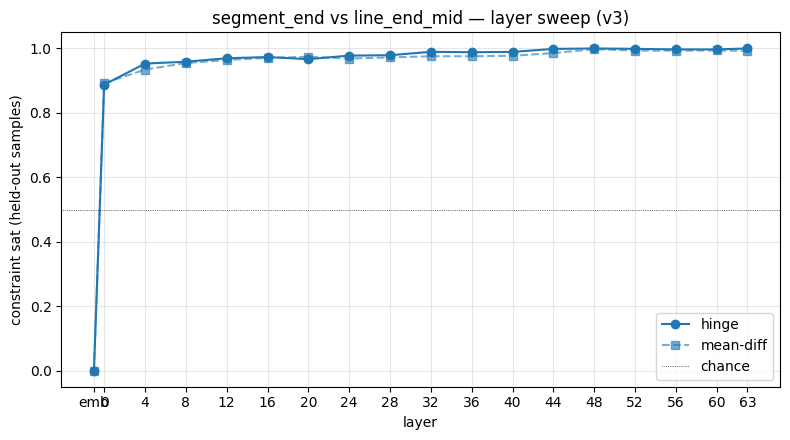

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
df = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in sweep_results])
df["x"] = df["layer"].map(_plot_x); df = df.sort_values("x")
ax.plot(df["x"], df["sat_test_opt"], "o-", color="tab:blue", label="hinge")
ax.plot(df["x"], df["sat_test_md"],  "s--", color="tab:blue", alpha=0.6, label="mean-diff")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out samples)")
ax.set_title("segment_end vs line_end_mid — layer sweep (v3)")
apply_layer_axis(ax)
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 6b. Raw vs token-demeaned sweep

Re-run the sweep with `DEMEAN` off and on. **Sanity check:** the `emb` point must
collapse under demeaning. **Real readout:** do deep layers stay above chance once
token identity is removed? (Interpret against the d+/d− overlap from §3b.)

emb sat:  raw=0.882  demeaned=0.000   (OK collapsed)


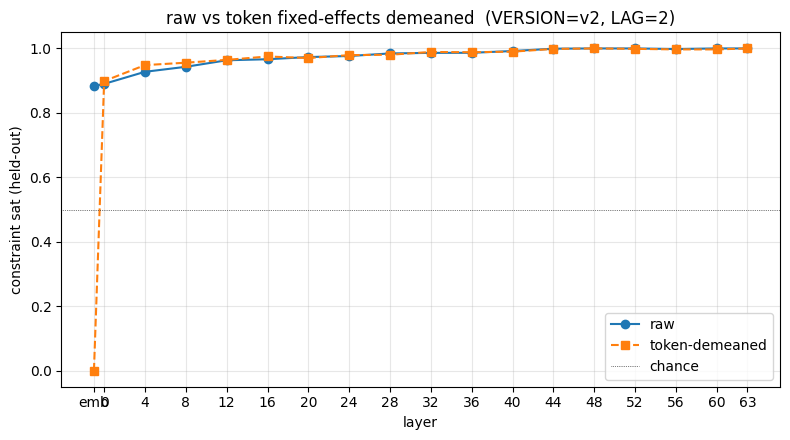

In [14]:
def _sweep_once(demean: bool):
    global DEMEAN
    DEMEAN = demean
    out = []
    for L in LAYER_KEYS:
        v_opt, _ = optimize_direction(pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
                                      margin=MARGIN, lr=LR, n_steps=N_STEPS)
        out.append({"layer": L, "sat": constraint_sat(v_opt, test_pairs, L)})
    return out

_prev_demean = DEMEAN
sweep_raw    = _sweep_once(False)
sweep_demean = _sweep_once(True)
DEMEAN = _prev_demean   # restore the caller's setting

emb_raw = next(r["sat"] for r in sweep_raw    if r["layer"] == "emb")
emb_dm  = next(r["sat"] for r in sweep_demean if r["layer"] == "emb")
print(f"emb sat:  raw={emb_raw:.3f}  demeaned={emb_dm:.3f}   "
      f"({'OK collapsed' if emb_dm < 0.6 else 'NOT collapsed — check'})")

fig, ax = plt.subplots(figsize=(8, 4.5))
for sweep, lab, sty in [(sweep_raw, "raw", "o-"), (sweep_demean, "token-demeaned", "s--")]:
    df = pd.DataFrame(sweep); df["x"] = df["layer"].map(_plot_x); df = df.sort_values("x")
    ax.plot(df["x"], df["sat"], sty, label=lab)
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out)")
ax.set_title(f"raw vs token fixed-effects demeaned  (VERSION={VERSION}, LAG={LAG})")
apply_layer_axis(ax); ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Where does the probe fire on a real generation?

Ground-truth `segment_end` tokens are wrapped in `[[ ]]`.

In [15]:
from circuitsvis.tokens import colored_tokens
from IPython.display import display

_GLYPH_NL = "\n↵"; _GLYPH_TAB = "⇥"; _GLYPH_DOT = "·"

def _vis_tok(s: str) -> str:
    s = s.replace("<", "\uff1c").replace(">", "\uff1e")
    s = s.replace("\n", _GLYPH_NL).replace("\r", _GLYPH_NL).replace("\t", _GLYPH_TAB)
    if s.strip() == "" and len(s) > 0:
        s = _GLYPH_DOT * len(s)
    return s

def get_v(layer=None, kind="opt"):
    L = best_layer if layer is None else layer
    row = next(r for r in sweep_results if r["layer"] == L)
    return row[f"v_{kind}"].to(torch.float32), L

@torch.no_grad()
def render_probe_activity_for_record(record, layer=None, kind="opt"):
    v, L = get_v(layer, kind)
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    input_ids = tokenized.input_ids[0]
    ly = layer_key_to_name(L)
    hs_dict = get_hs(mt=mt, input=tokenized,
                     locations=[(ly, t) for t in range(len(input_ids))], return_dict=True)
    scores = []
    for t in range(len(input_ids)):
        h = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
        scores.append(((h / (h.norm() + 1e-9)) * v).sum().item())

    # ground-truth segment_end PROBED positions (token_pos = label - LAG) — the
    # tokens whose latents the probe is actually read from. Marked with [[ ]].
    seg_end = {r.token_pos for r in all_rows
               if (r.sample_name, r.modularity) == (record["sample_name"], record["modularity"])
               and r.role == "segment_end"}
    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids]
    marked = [f"[[{tok}]]" if i in seg_end else tok for i, tok in enumerate(tokens)]

    print(f"sample={record['sample_name']}  modularity={record['modularity']}  layer={_layer_label(L)}  kind={kind}")
    print(f"score range: [{min(scores):.3f}, {max(scores):.3f}]")
    print("=" * 80)
    display(colored_tokens(marked, scores, positive_color="seagreen", negative_color="firebrick"))

held_out_records = [r for r in records if r["sample_name"] in test_names]
demo = [d for d in held_out_records if d["modularity"] == "monolithic"][6]
render_probe_activity_for_record(demo, layer=None, kind="opt")

sample=ngram_freq  modularity=monolithic  layer=48  kind=opt
score range: [-0.144, 0.192]


In [16]:
from src.goals.data import IncompleteCodeSample
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.goalscope import greedy_continue
from rich.markup import escape
from src.tokens import prepare_input
from src.goals.multistep_data import MultiStepDataset, MultiStepSample

def build_prompt(mt, sample: MultiStepSample, modularity: str | None = None) -> str:
    """Render the prompt for a given (sample, modularity) without mutating sample."""
    modularity = modularity or sample.modularity
    instruction = sample.render_instruction(modularity=modularity)
    code_stub = sample.render_code_stub(modularity=modularity)
    if supports_chat_template(mt):
        return apply_chat_template(
            mt=mt,
            user_query=instruction.strip(),
            incomplete_code=code_stub,
        )
    return instruction + "\nAnswer:" + code_stub

ds = MultiStepDataset.load_dataset()
test_sample = ds.samples[0]

# test_sample.no_comment_str = """Before you complete one of the mentioned steps, write a comment `# Start 'STEP <step_no>'` and after you complete the step, write a comment `# End 'STEP <step_no>'`. Make sure that you code is also well decomented with appropriate comments."""
test_sample.no_comment_str = """Before you complete one of the mentioned steps, write a comment `# Start 'STEP <step_no>'` and after you complete the step, write a comment `# End 'STEP <step_no>'`. Make sure that your code doesn't have any other comments other than the step comments."""
test_sample.without_comments = True
test_sample.modularity = "monolithic"

test_prompt = build_prompt(mt, test_sample, test_sample.modularity)
test_prompt = test_prompt.replace("Write a python code", "Write a code in C++")
test_prompt = test_prompt.replace("def main():", "int main() {")


print(test_prompt)

test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=1024,
)
rich_print(f"[white]{escape(test_prompt)}[/white][sea_green3]{escape(test_gen)}[/sea_green3]")

2026-06-07 16:45:41 src.goals.multistep_data INFO     loaded MultiStepDataset: 106 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/seed.json
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a code in C++ that does the following:

1. Read a CSV file from a given path and return its rows as a list of dictionaries.
2. Build a dictionary that maps each unique value in a chosen column to the list of rows that contain it.
3. Given a key, return the matching rows from the index in O(1) lookup, or an empty list if the key is absent.
4. Read a CSV path, a column name, and a query key from the command line, then print the matching rows.

Put all the logic inside a single function `main()` (taking no arguments) — do not define any helper functions. If a step requires reading from a file path, the co

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a code in C++ that does the following:

1. Read a CSV file from a given path and return its rows as a list of dictionaries.
2. Build a dictionary that maps each unique value in a chosen column to the list of rows that contain it.
3. Given a key, return the matching rows from the index in O(1) lookup, or an empty list if the key is absent.
4. Read a CSV path, a column name, and a query key from the command line, then print the matching rows.

Put all the logic inside a single function `main()` (taking no arguments) — do not define any helper functions. If 
a step requires reading from a file path, the command line, or standard input, do that inside `main()` as well.
Before you complete one of the mentioned steps, write a comment `# Start 'STEP <step_no>'` and after you complete 
the step, write a comment `# End 'STEP <step_no>'`. Make sure that your code doesn't have any other comments other 
than the step comments.<|im_end|>
<|im_start|>assistant
<code>
int main() {
    #include <iostream>
    #include <fstream>
    #include <sstream>
    #include <vector>
    #include <map>
    #include <string>
    #include <unordered_map>

    using namespace std;

    # Start 'STEP 1'
    string csv_path, column_name, query_key;
    cin >> csv_path >> column_name >> query_key;

    ifstream file(csv_path);
    if (!file.is_open()) {
        cerr << "Failed to open file." << endl;
        return 1;
    }

    string line;
    getline(file, line);
    stringstream ss(line);
    string token;
    vector<string> headers;
    while (getline(ss, token, ',')) {
        headers.push_back(token);
    }

    vector<unordered_map<string, string>> rows;
    while (getline(file, line)) {
        stringstream ss(line);
        unordered_map<string, string> row;
        for (const auto& header : headers) {
            getline(ss, token, ',');
            row[header] = token;
        }
        rows.push_back(row);
    }
    file.close();
    # End 'STEP 1'

    # Start 'STEP 2'
    unordered_map<string, vector<unordered_map<string, string>>> index;
    for (const auto& row : rows) {
        auto it = row.find(column_name);
        if (it != row.end()) {
            index[it->second].push_back(row);
        }
    }
    # End 'STEP 2'

    # Start 'STEP 3'
    auto it = index.find(query_key);
    vector<unordered_map<string, string>> result;
    if (it != index.end()) {
        result = it->second;
    }
    # End 'STEP 3'

    # Start 'STEP 4'
    for (const auto& row : result) {
        for (const auto& [key, value] : row) {
            cout << key << ": " << value << ", ";
        }
        cout << endl;
    }
    # End 'STEP 4'

    return 0;
}
</code>

In [17]:
from src.tokens import find_token_range


@torch.no_grad()
def _score_text_tokens(text, layer=None, kind="opt"):
    """Project the trained probe (sweep_results) onto every token of `text`."""
    v, L = get_v(layer, kind)
    tokenized = prepare_input(prompts=text, tokenizer=mt)
    input_ids = tokenized.input_ids[0]
    ly = layer_key_to_name(L)
    hs_dict = get_hs(mt=mt, input=tokenized,
                     locations=[(ly, t) for t in range(len(input_ids))], return_dict=True)
    scores = []
    for t in range(len(input_ids)):
        h = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
        scores.append(((h / (h.norm() + 1e-9)) * v).sum().item())
    return input_ids, scores, L


@torch.no_grad()
def render_probe_activity_for_text(text, layer=None, kind="opt", start_from=None):
    """Score every token of `text` with full context; `start_from` slices only the
    DISPLAY (not the scoring) to begin at the first occurrence of that substring."""
    input_ids, scores, L = _score_text_tokens(text, layer=layer, kind=kind)
    start_pos = 0
    if start_from is not None:
        tokenized = prepare_input(prompts=text, tokenizer=mt, return_offsets_mapping=True)
        offsets = tokenized.pop("offset_mapping")[0]
        start_pos, _ = find_token_range(string=text, substring=start_from, offset_mapping=offsets)
    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids[start_pos:]]
    sliced = scores[start_pos:]
    print(f"layer={_layer_label(L)}  kind={kind}  (showing {len(tokens)} tokens)")
    print(f"score range: [{min(sliced):.3f}, {max(sliced):.3f}]")
    print("=" * 80)
    display(colored_tokens(tokens, sliced, positive_color="seagreen", negative_color="firebrick"))

render_probe_activity_for_text(test_prompt + test_gen, layer=None, kind="opt")

layer=48  kind=opt  (showing 715 tokens)
score range: [-0.089, 0.202]


## 8. Causal test — does injecting the transition direction end the step early?

Idea: cut a generation **mid-way through a step's code**, then continue greedily
while **adding the trained probe direction** (the `segment_end`/transition signal)
to the residual stream of every newly generated token. If the direction is causal,
the model should *prematurely* stop the step and emit `# End 'STEP <X>'` (and start
the next step), rather than finishing the current step's logic.

Qualitative only — tweak `STEER_RECORD` / `STEER_STEP` / `STEER_FRAC` (where to cut),
`DIR_LAYER` / `DIR_KIND` (which probe direction), `STEER_LAYERS` (where to inject),
and `COEFFS` (strength; `0.0` = baseline). Steering vectors are rescaled per layer to
`coeff × ‖residual‖`, following nb 16's additive-steering recipe.

In [18]:
from src.functional import PatchSpec, generate_with_patch, get_hs
from src.tokens import prepare_input
from rich.markup import escape
import re

# ---------------- config ----------------
DIR_LAYER = best_layer          # which trained probe direction to inject
DIR_KIND  = "opt"               # 'opt' (hinge) or 'md' (mean-diff)
STEER_LAYERS = [L for L in range(DIR_LAYER - 8, DIR_LAYER + 1) if 0 <= L < mt.n_layer]
# COEFFS    = [0.0, 0.06, 0.12, 0.20]   # 0.0 == baseline (no steering)
COEFFS = [0.0, 0.1]
MAX_NEW   = 128
SRC_TOKEN_RANGE = list(range(-5, 0))   # tail positions used to scale the vector


def _probe_dir(layer=None, kind=None):
    layer = DIR_LAYER if layer is None else layer
    kind = DIR_KIND if kind is None else kind
    row = next(r for r in sweep_results if r["layer"] == layer)
    return row[f"v_{kind}"].to(torch.float32)


def build_prefix_mid_step(record, step_idx, frac=0.5):
    """Prefix = full_prompt + generation truncated to `frac` into step `step_idx`'s
    code, at a token boundary. Returns (prefix_text, cut_tok, n_step_tokens)."""
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    offs = mt.tokenizer(combined, return_offsets_mapping=True,
                        add_special_tokens=False)["offset_mapping"]
    t0, t1 = lab.labels[step_idx].gen_token_range
    cut_tok = t0 + max(1, int((t1 - t0) * frac))
    cut_char = offs[cut_tok][0]
    return combined[:cut_char], cut_tok, t1 - t0


@torch.no_grad()
def steer_continue(prefix_text, coeff, layers=None, dir_layer=None, kind=None, max_new=None):
    layers = STEER_LAYERS if layers is None else layers
    max_new = MAX_NEW if max_new is None else max_new
    inputs = prepare_input(prompts=prefix_text, tokenizer=mt)
    if coeff == 0.0:
        return generate_with_patch(
            mt=mt, inputs=inputs, patches=[], n_gen_per_prompt=1,
            max_new_tokens=max_new, patch_interface="baukit",
            remove_prefix=True, do_sample=False,
        )[0]
    v = _probe_dir(dir_layer, kind)
    src_hs = get_hs(
        mt=mt, input=prefix_text,
        locations=[(mt.layer_names[L], t) for L in layers for t in SRC_TOKEN_RANGE],
        return_dict=True,
    )
    patches = []
    for L in layers:
        h = torch.stack([src_hs[(mt.layer_names[L], t)].float() for t in SRC_TOKEN_RANGE]).mean(0)
        scaled = v.to(h.device) * (coeff * h.norm() / (v.norm() + 1e-9))
        patches.append(PatchSpec(location=(mt.layer_names[L], -1),
                                 patch=scaled, strategy="add", on_pass="all"))
    return generate_with_patch(
        mt=mt, inputs=inputs, patches=patches, n_gen_per_prompt=1,
        max_new_tokens=max_new, patch_interface="baukit",
        remove_prefix=True, do_sample=False,
    )[0]


def _report(cont: str, tag: str):
    m = re.search(r"#\s*End\s*'?STEP", cont)
    if m:
        flag = f"[bold green]→ emits End-marker @ char {m.start()}[/bold green]"
    else:
        flag = "[red]no End-marker[/red]"
    rich_print(f"\n[bold yellow]══ {tag} ══[/bold yellow]   {flag}")
    rich_print(f"[salmon1]{escape(cont)}[/salmon1]")

In [19]:
# ---- pick an example + cut point ----
STEER_RECORD = next(r for r in records
                    if r["modularity"] == "modular" and len(r["labeled"].labels) >= 3)
STEER_STEP = 1      # which step to cut into
STEER_FRAC = 0.5    # how far into that step's code to cut

prefix, cut_tok, n_step = build_prefix_mid_step(STEER_RECORD, STEER_STEP, STEER_FRAC)
rich_print(f"[bold]sample={STEER_RECORD['sample_name']}  step={STEER_STEP}  frac={STEER_FRAC}  "
           f"cut_tok={cut_tok} (step has {n_step} gen tokens)[/bold]")
rich_print(f"[bold]dir_layer={DIR_LAYER}  kind={DIR_KIND}  "
           f"steer_layers={STEER_LAYERS[0]}..{STEER_LAYERS[-1]}[/bold]")
rich_print("[grey58]── prefix tail (last ~300 chars) ──[/grey58]")
rich_print(f"[grey58]{escape(prefix[-300:])}[/grey58]")

steer_outputs = {}   # coeff -> continuation (rendered with the probe in §8.1)
for coeff in COEFFS:
    tag = "baseline" if coeff == 0.0 else f"coeff={coeff}"
    cont = steer_continue(prefix, coeff)
    steer_outputs[coeff] = cont
    _report(cont, tag)

sample=acronym_expander  step=1  frac=0.5  cut_tok=340 (step has 71 gen tokens)

dir_layer=48  kind=opt  steer_layers=40..48

── prefix tail (last ~300 chars) ──

ir full forms.
    """
    with open(file_path, 'r') as file:
        glossary = json.load(file)
    return glossary
# End 'STEP 1'

# Start 'STEP 2'
def read_target_text(file_path):
    """
    Reads the content of a text file into a single string.
    
    :param file_path: Path to the text file.

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


══ baseline ══   → emits End-marker @ char 153

    :return: String containing the entire content of the file.
    """
    with open(file_path, 'r') as file:
        text = file.read()
    return text
# End 'STEP 2'

# Start 'STEP 3'
def expand_acronyms(text, glossary):
    """
    Replaces whole-word occurrences of acronyms in the text with 'acronym (full form)'.
    
    :param text: The original text where acronyms need to be expanded.
    :param glossary: Dictionary mapping acronyms to their full forms.
    :return: Text with expanded acron

══ coeff=0.1 ══   → emits End-marker @ char 159

    :return: String containing the entire content of the file.
    """
    with open(file_path, 'r') as file:
        content = file.read()
    return content
# End 'STEP 2'

# End 'STEP 2'
# Start 'STEP 3'
def expand_acronyms(text, glossary):
    """
    Replaces whole-word occurrences of acronyms in the text with 'acronym (full form)'.
    
    :param text: The input text where acronyms need to be expanded.
    :param glossary: Dictionary mapping acronyms to their full forms.
    :